In [13]:
import matplotlib.pyplot as plt
import numpy as np

from src.experiments.linear.setup import setup

from src import datasets
from src.networks import MLP, CNN
from src.utils.krr import sweep_krr
from src.rp_slam.training import Trainer as RPTrainer
from src.svae_slam.training import Trainer as SVAETrainer

## Linear Dataset

In [14]:
DATASEED = 0
DATASET = datasets.load_dataset("linear_medium", DATASEED)
DATASET = DATASET.standardized_data

N, T = DATASET.train_data[0].shape[:2]
OBS_DIM = DATASET.train_data[0].reshape(N, T, -1).shape[-1]

## Helper Functions

In [15]:
def train(
    kernel: str,
    latent_dim: int = 16,
    batch_size: int = 32,
    num_iter: int = 2500,
    seed: int = 1234,
    prior_lr: float = 1e-3,
    rec_lr: float = 1e-3,
    dec_lr: float = 1e-3,
    plot: bool = True
):
    
    CONFIG, MODEL_FE = setup(
        kernel=kernel,
        obs_dim=OBS_DIM,
        latent_dim=latent_dim, 
        batch_size=batch_size, 
        num_iter=num_iter, 
        seed=seed,
        prior_lr=prior_lr, 
        rec_lr=rec_lr,
        dec_lr=dec_lr,
    )
    # trainer = Trainer(model=MODEL_FE, config=CONFIG)
    if kernel == "svae" or kernel == "ramp-svae":
        trainer = SVAETrainer(model=MODEL_FE, config=CONFIG)
    else: 
        trainer = RPTrainer(model=MODEL_FE, config=CONFIG)
        
    trainer.fit(data=DATASET.train_data, use_pbar=True)

    # plot loss over time
    if plot:
        plt.figure(figsize=(14, 3))
        plt.plot(trainer.loss_tot)
        plt.title("Training loss over iterations")
        plt.xlabel("Iteration")
        plt.ylabel("Loss")
        plt.show()
    
    return trainer

In [16]:
def kernel_ridge_regression(
    x,
    val_x,
    plot: bool = True
):
    
    sigma_range = np.arange(4, 9, 0.1)
    lambda_range = np.arange(0.001, 0.2, 0.02)
    
    krr, scores = sweep_krr(
        x,
        DATASET.train_states,
        val_x,
        DATASET.val_states,
        sigma_range, 
        lambda_range,
        batch_frac=0.2
    )

    if plot:
        values = np.asarray(scores)
        sigmas = np.asarray(sigma_range)
        lambdas = np.asarray(lambda_range)

        fig, ax = plt.subplots(figsize=(10, 6))
        im = ax.imshow(values, origin="lower", aspect="auto", cmap="viridis")

        ax.set_xticks(np.arange(len(lambdas)))
        ax.set_xticklabels([f"{v:.3f}" for v in lambdas], rotation=45)

        rows = np.arange(0, len(sigmas), 4)
        ax.set_yticks(rows)
        ax.set_yticklabels([f"{sigmas[i]:.2f}" for i in rows])

        i, j = np.unravel_index(np.nanargmax(values), values.shape)
        ax.scatter(j, i, marker="x", color="red", s=100, linewidths=2)

        ax.set(xlabel=r"$\lambda$", ylabel=r"$\sigma$", title=f"Validation $R^2$ — best: {values[i, j]:.3f}")
        fig.colorbar(im, ax=ax, label=r"Mean $R^2$")
        plt.tight_layout()
        plt.show()

    return krr

In [17]:
def plot_visual_diagnostics(preds, truth, B: int = 3):

    preds = np.asarray(preds)
    truth = np.asarray(truth)
    D = preds.shape[-1]
    K =truth.shape[-1]

    # plot example regressions
    for b in range(B):
        fig, ax = plt.subplots(1, K, figsize=(15, 2))
        for k in range(K):
            ax[k].plot(DATASET.val_states[b, :, k], label="Truth")
            ax[k].plot(preds[b, :, k], label="Predicted")
            ax[k].legend(fontsize=6)
    plt.show()

    # plot fit 
    fig, axes = plt.subplots(1, D, figsize=(4 * D, 4), squeeze=False)
    
    for d, ax in enumerate(axes.ravel()):
        x = truth[:, :, d].ravel()
        y = preds[:, :, d].ravel()
    
        # Least-squares line of best fit
        slope, intercept = np.polyfit(x, y, 1)
        x_fit = np.linspace(x.min(), x.max(), 100)
        y_fit = slope * x_fit + intercept
    
        # R-squared
        r2 = 1 - np.sum((y - (slope * x + intercept))**2) / np.sum((y - y.mean())**2)
    
        ax.scatter(x, y, s=3, alpha=0.3)
        ax.plot(x_fit, y_fit, color="red", lw=1.5, label=f"Fit ($R^2={r2:.3f}$)")
        ax.plot(x_fit, x_fit, "k--", lw=1, label="Ideal")
    
        ax.set_title(f"Dimension {d + 1}")
        ax.set_xlabel("Truth")
        ax.set_ylabel("Predicted")
        ax.legend(fontsize=12)
    
    plt.tight_layout()
    plt.show()
    

## SVAE

Training: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2500/2500 [03:04<00:00, 13.57it/s, loss=0.576]


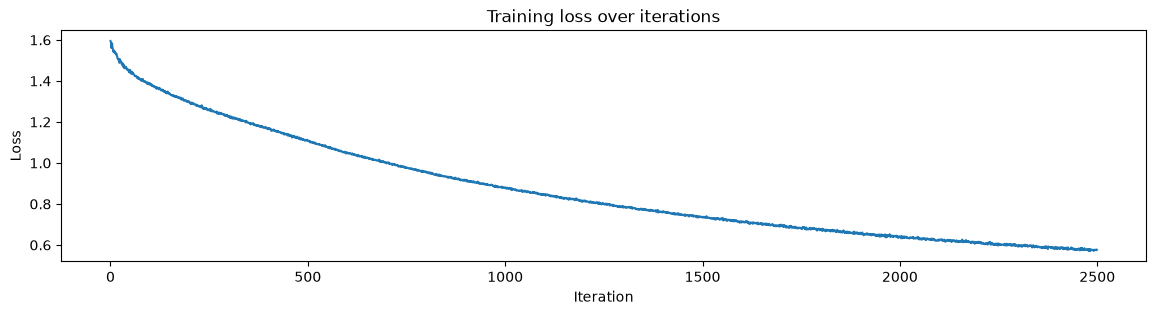

In [6]:
svae = train(kernel="svae")

Fitting KRR: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:15<00:00, 31.43it/s, best_r2=0.9487]


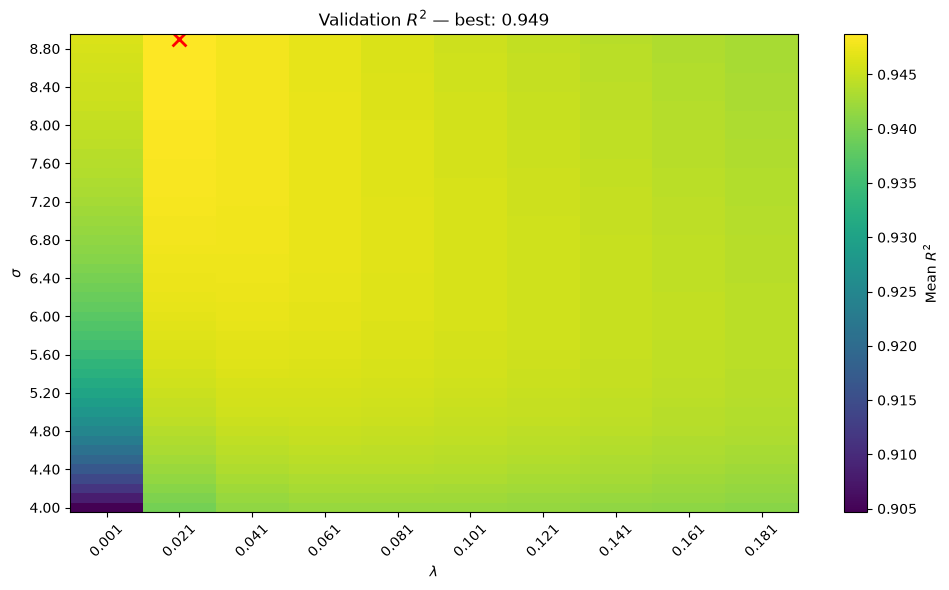

In [9]:
x = svae.apply(DATASET.train_data).params["means"]
val_x = svae.apply(DATASET.val_data).params["means"]
krr = kernel_ridge_regression(x, val_x)

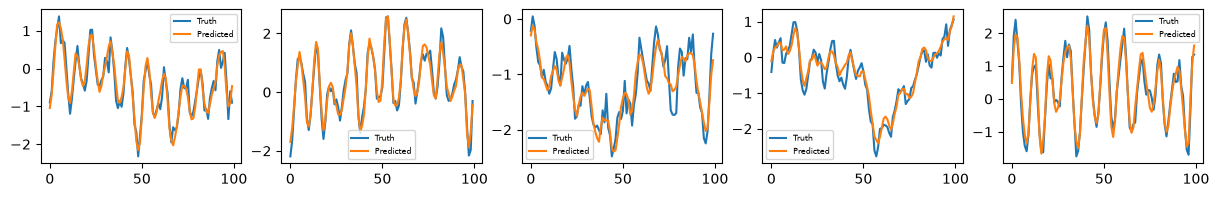

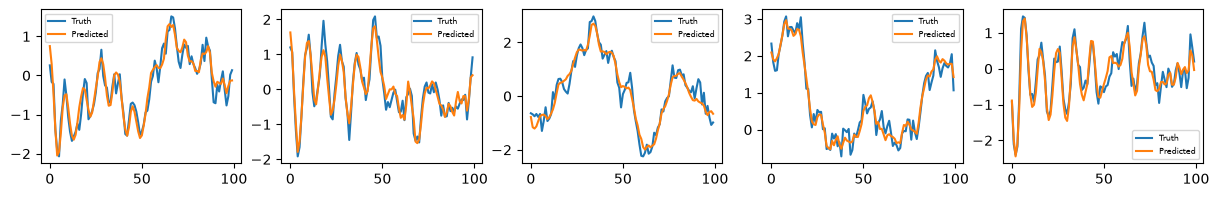

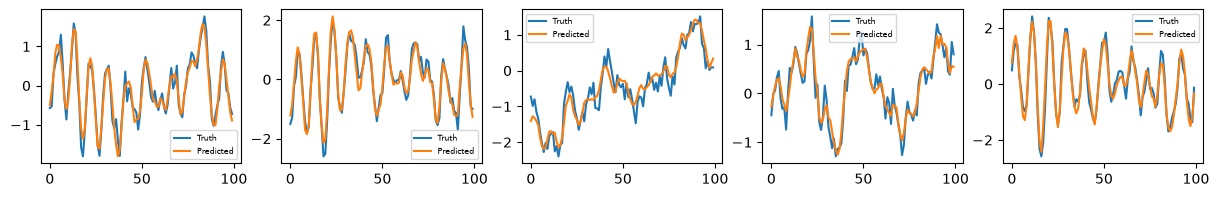

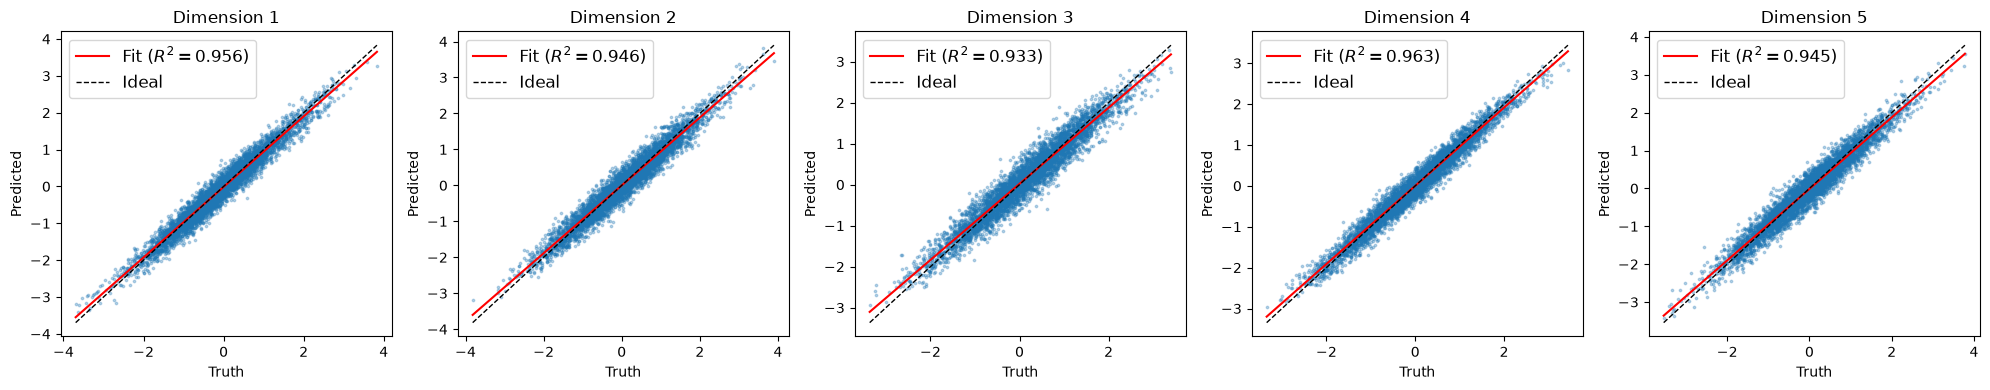

In [10]:
preds = krr.predict(val_x)
truth = DATASET.val_states
plot_visual_diagnostics(preds, truth)

## RAMP-SVAE

Training: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2500/2500 [03:28<00:00, 12.01it/s, loss=0.512]


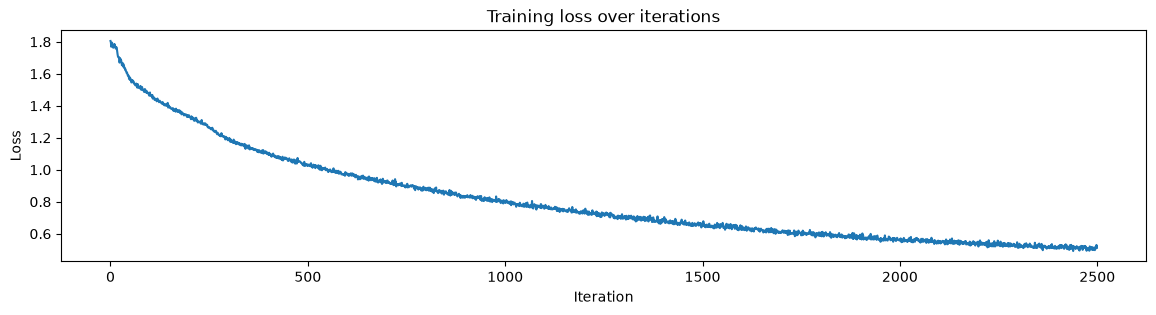

In [18]:
ramp_svae = train(kernel="ramp-svae")

Fitting KRR: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:18<00:00, 27.69it/s, best_r2=0.9554]


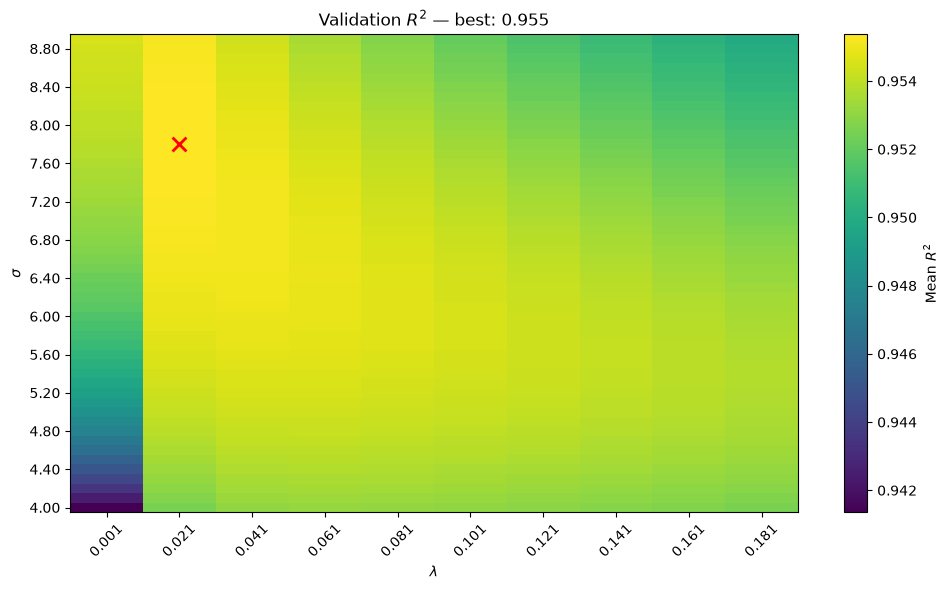

In [20]:
x = ramp_svae.apply(DATASET.train_data).params["mean"]
val_x = ramp_svae.apply(DATASET.val_data).params["mean"]
krr = kernel_ridge_regression(x, val_x)

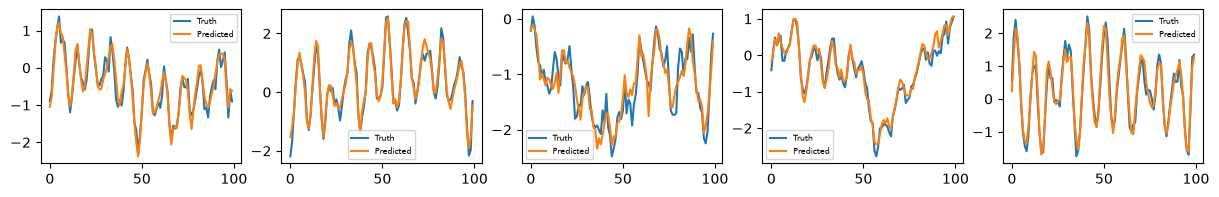

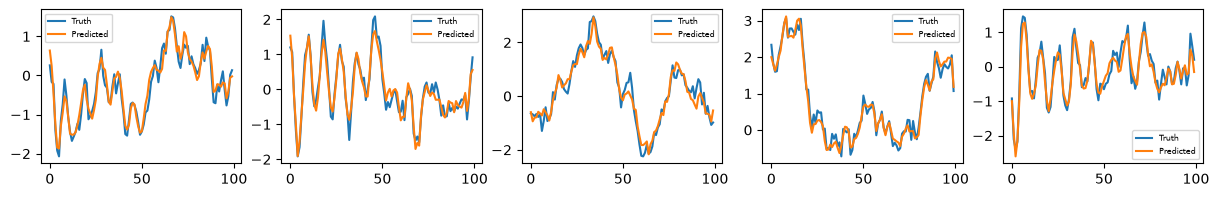

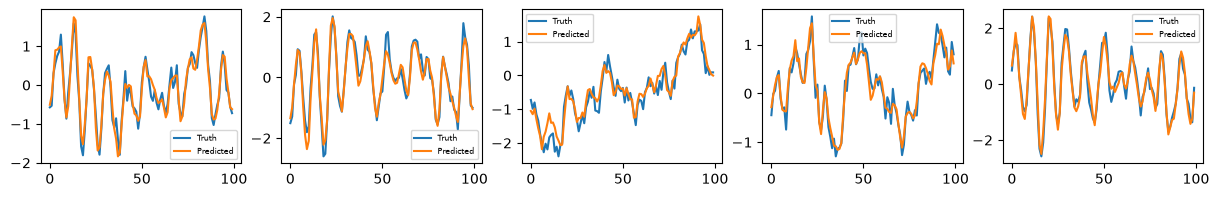

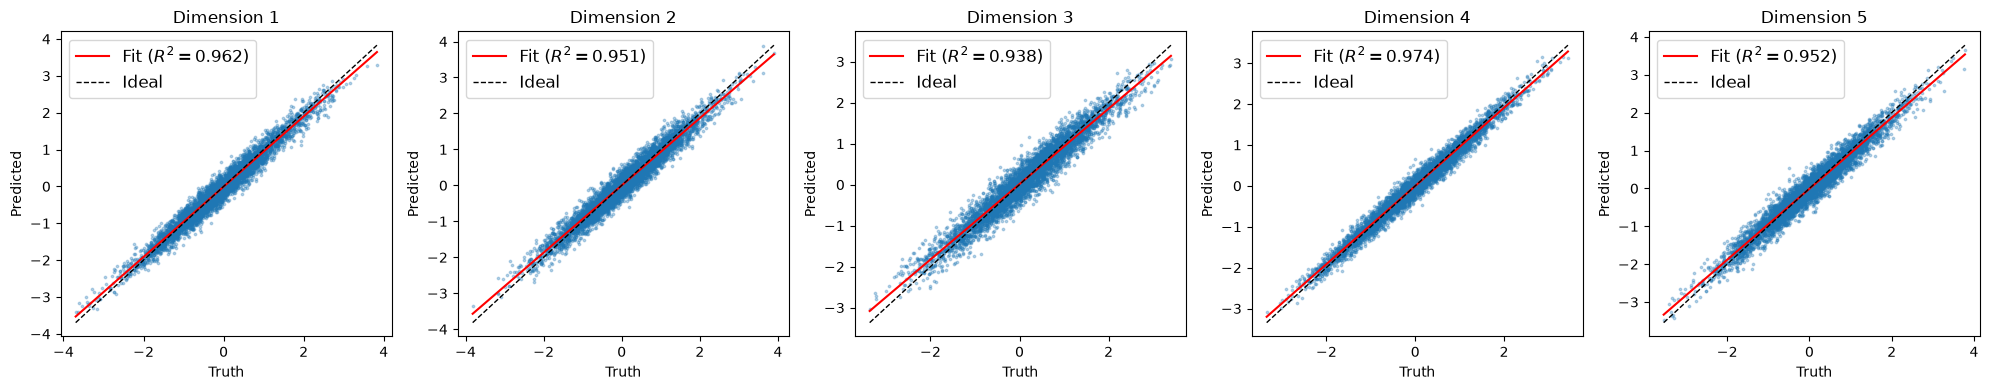

In [21]:
preds = krr.predict(val_x)
truth = DATASET.val_states
plot_visual_diagnostics(preds, truth)